## 1. Imports et configuration

In [1]:
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device :', device)

Device : cpu


## 2. Chemins et paramètres

`ImageFolder` déduit automatiquement les labels à partir des sous-dossiers.

In [ ]:
DATA_DIR = Path('food-11')
TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'
MODEL_PATH = Path('simple_food11_model.pth')

IMAGE_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-3

print('Classes disponibles :', sorted(path.name for path in TRAIN_DIR.iterdir() if path.is_dir()))

Classes disponibles : ['bread', 'dairy', 'dessert', 'egg', 'fried', 'meat', 'noodles-pasta', 'rice', 'seafood', 'soup', 'vegetable-fruit']


## 3. Inspecter quelques images

13296 images dentraînement
11 classes : ['bread', 'dairy', 'dessert', 'egg', 'fried', 'meat', 'noodles-pasta', 'rice', 'seafood', 'soup', 'vegetable-fruit']


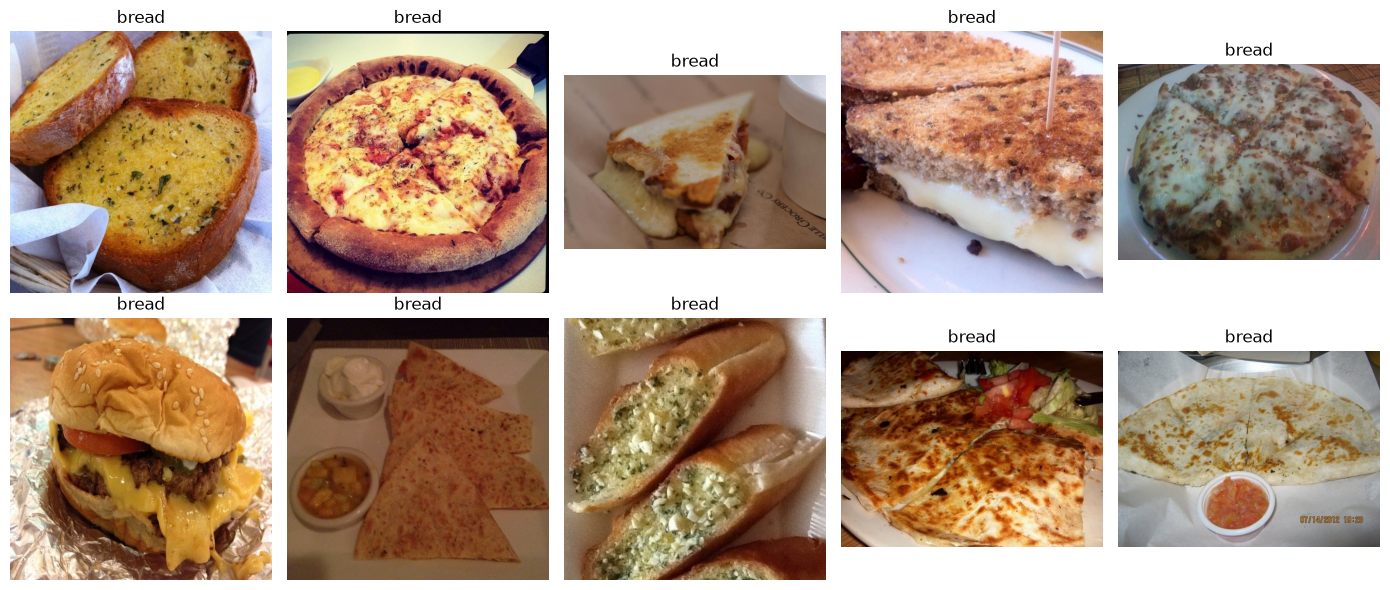

In [10]:
preview_dataset = datasets.ImageFolder(TRAIN_DIR)
class_names = preview_dataset.classes
print(f'{len(preview_dataset)} images dentraînement')
print(f'{len(class_names)} classes : {class_names}')

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, (image, label) in zip(axes.ravel(), preview_dataset.samples[:10]):
    ax.imshow(plt.imread(image))
    ax.set_title(class_names[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Transformations et DataLoaders

Les images sont redimensionnées avec la valeur IMAGE_SIZE définie, on applique une transformation aléatoire en rotation pour éviter l'overfitting. L'augmentation est appliquée uniquement à l'entraînement.

- ImageFolder parcourt les dossiers et étiquette chaque image selon le nom du répertoire (pytorch crée un dictionnaire class_to_idx qui relie le num d'étiquette à une catégorie) (trois matrices de 128×128 superposées : une matrice Rouge, une Verte, une Bleue, étiquette)

- Le DataLoader crée des lots de taille batch size (indépendamment de la classe d'origine) et les envoie au modèle pendant l'entrainement

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)

class_names = train_dataset.classes
num_classes = len(class_names)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print(f'Train : {len(train_dataset)} images, {len(train_loader)} lots')
print(f'Test  : {len(test_dataset)} images, {len(test_loader)} lots')

Train : 13296 images, 416 lots
Dataset ImageFolder
    Number of datapoints: 13296
    Root location: food-11/train
    StandardTransform
Transform: Compose(
               Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
               ToTensor()
           )
Test  : 3097 images, 97 lots


## 5. Vérifier la forme d'un lot

In [13]:
images, labels = next(iter(train_loader))
print('Images :', images.shape)
print('Labels :', labels.shape)
print('Exemple de labels :', labels[:10].tolist())

Images : torch.Size([32, 3, 128, 128])
Labels : torch.Size([32])
Exemple de labels : [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 6. Définir le modèle

Comme `SimpleNet` dans `pytruc.py`, le modèle renvoie des logits et utilise `CrossEntropyLoss`. Ici, des convolutions extraient les caractéristiques visuelles avant le classifieur.

In [14]:
class Model(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = Model(num_classes).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)

Model(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=11, bias=True)
  )
)


## 7. Fonctions d'entraînement et d'évaluation

Ces deux fonctions reprennent directement le rôle de `train_one_epoch` et `evaluate` de `pytruc.py`.

In [15]:
def train_one_epoch(model, dataloader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        predictions = model(X)
        loss = loss_fn(predictions, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X.size(0)
        correct += (predictions.argmax(dim=1) == y).sum().item()
        total += X.size(0)

    return total_loss / total, correct / total


def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            predictions = model(X)
            loss = loss_fn(predictions, y)
            total_loss += loss.item() * X.size(0)
            correct += (predictions.argmax(dim=1) == y).sum().item()
            total += X.size(0)

    return total_loss / total, correct / total

## 8. Entraîner le modèle

In [16]:
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
    test_loss, test_acc = evaluate(model, test_loader, loss_fn, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_acc)
    print(
        f'Epoch {epoch:02d}/{EPOCHS} | '
        f'train_loss={train_loss:.4f} | train_acc={train_acc:.3f} | '
        f'test_loss={test_loss:.4f} | test_acc={test_acc:.3f}'
    )

Epoch 01/10 | train_loss=3.0199 | train_acc=0.334 | test_loss=2.5577 | test_acc=0.161
Epoch 02/10 | train_loss=2.0664 | train_acc=0.300 | test_loss=2.9447 | test_acc=0.161
Epoch 03/10 | train_loss=1.8823 | train_acc=0.303 | test_loss=3.0482 | test_acc=0.161
Epoch 04/10 | train_loss=1.6878 | train_acc=0.370 | test_loss=5.7384 | test_acc=0.075
Epoch 05/10 | train_loss=1.6800 | train_acc=0.373 | test_loss=3.6959 | test_acc=0.161
Epoch 06/10 | train_loss=1.5999 | train_acc=0.382 | test_loss=3.7968 | test_acc=0.161
Epoch 07/10 | train_loss=2.0351 | train_acc=0.245 | test_loss=2.5278 | test_acc=0.161


KeyboardInterrupt: 

## 9. Visualiser les courbes d'apprentissage

In [ ]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs, history['train_loss'], label='Train')
axes[0].plot(epochs, history['test_loss'], label='Test')
axes[0].set_title('Perte')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(epochs, history['train_acc'], label='Train')
axes[1].plot(epochs, history['test_acc'], label='Test')
axes[1].set_title('Exactitude')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

## 10. Évaluation détaillée

On calcule une matrice de confusion et un rapport par classe.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

all_predictions = []
all_labels = []
model.eval()
with torch.no_grad():
    for X, y in test_loader:
        predictions = model(X.to(device)).argmax(dim=1).cpu()
        all_predictions.extend(predictions.tolist())
        all_labels.extend(y.tolist())

print(classification_report(all_labels, all_predictions, target_names=class_names, zero_division=0))

matrix = confusion_matrix(all_labels, all_predictions)
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False
)
plt.tight_layout()
plt.show()

## 11. Afficher quelques prédictions

In [ ]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
images, labels = next(iter(test_loader))
with torch.no_grad():
    predictions = model(images.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, image, label, prediction in zip(axes.ravel(), images[:10], labels[:10], predictions[:10]):
    image = (image * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    color = 'green' if label == prediction else 'red'
    ax.set_title(f'Vrai : {class_names[label]}\nPrédit : {class_names[prediction]}', color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 12. Sauvegarder et recharger le modèle

In [ ]:
torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': class_names,
    'image_size': IMAGE_SIZE,
}, MODEL_PATH)
print(f'Modèle sauvegardé dans : {MODEL_PATH}')

checkpoint = torch.load(MODEL_PATH, map_location=device)
loaded_model = Model(len(checkpoint['class_names'])).to(device)
loaded_model.load_state_dict(checkpoint['model_state_dict'])
loaded_model.eval()
print('Modèle rechargé avec succès.')